![The Bridge - Matplotlib](../img/banner_thebridge_matplotlib.png)

# Visualización con Matplotlib: Scatter Plots (Diagramas de dispersión)

Otro tipo de gráfico comúnmente utilizado es el gráfico de dispersión, un pariente cercano del gráfico de líneas, y muy habitual en los análisis bivariantes.

En lugar de que los puntos estén unidos por segmentos de línea, aquí los puntos se representan individualmente con un punto, círculo u otra forma.

Comenzamos con nuestras importaciones:

In [1]:
# %matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np
import pandas as pd

### Gráficos de dispersión con ``plt.plot`` y ``ax.plot``

En la sesión de líneas sencillas vimos ``plt.plot``/``ax.plot`` para producir gráficos de líneas.
Resulta que esta misma función también puede producir gráficos de dispersión, con solo cambiar algunos argumentos:

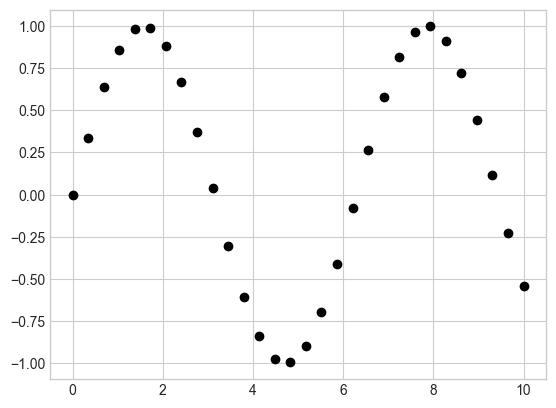

In [2]:
x = np.linspace(0, 10, 30)
y = np.sin(x)

plt.plot(x, y, 'o', color='black');

El tercer argumento en la llamada a la función es un carácter que representa el tipo de símbolo utilizado para el trazado. Al igual que puedes especificar opciones como ``'-'``, ``'--'`` para controlar el estilo de línea, el estilo del marcador tiene su propio conjunto de códigos de cadena cortos.  

La lista completa de símbolos disponibles se puede ver en la [documentación de ``plt.plot``](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html), o en la documentación en línea de Matplotlib. La mayoría de las posibilidades son bastante intuitivas, y aquí mostraremos algunas de las más comunes:

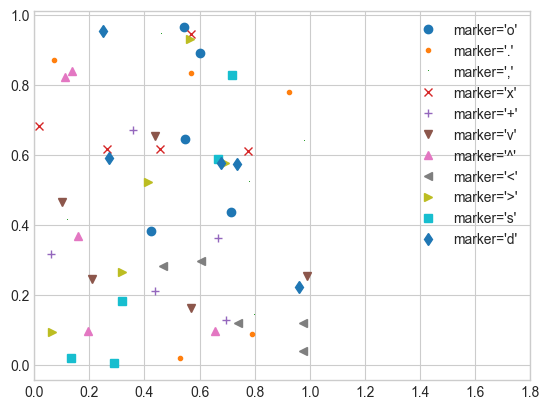

In [3]:
markers = ['o', '.', ',', 'x', '+', 'v', '^', '<', '>', 's', 'd']
rng = np.random.RandomState(0)
for marker in markers:
    plt.plot(rng.rand(5), rng.rand(5), marker,
             label=f"marker='{marker}'")
plt.legend(numpoints=1)
plt.xlim(0, 1.8);

Para aún más posibilidades, estos códigos de caracteres pueden ser utilizados junto con códigos de línea y color para trazar puntos junto con una línea que los conecte:

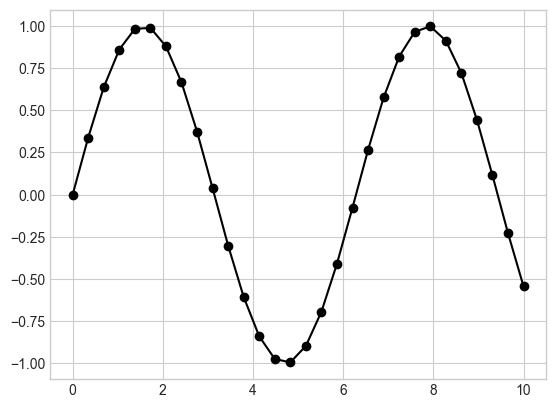

In [4]:
plt.plot(x, y, '-ok');  # línea (-), marcador círculo (o), color negro (k)

Otros argumentos de ``plt.plot`` permiten ajustar muchas propiedades de las líneas y los marcadores:

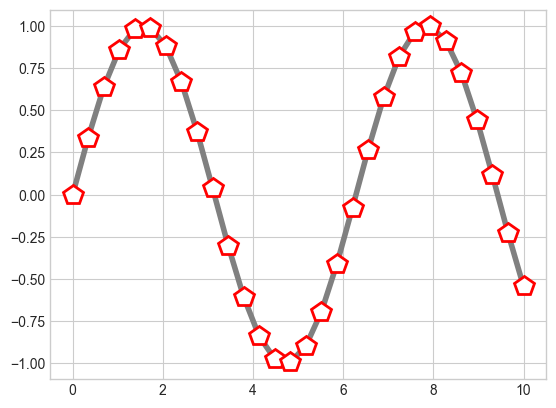

In [5]:
plt.plot(x, y, '-p', color='gray',
         linewidth=4,
         markersize=15,
         markerfacecolor='white',
         markeredgecolor='red',
         markeredgewidth=2);

### Gráficos de dispersión con ``plt.scatter`` y ``ax.scatter``

Un segundo método más potente para crear gráficos de dispersión es la función ``plt.scatter``, que se puede usar de manera muy similar a la función ``plt.plot``:

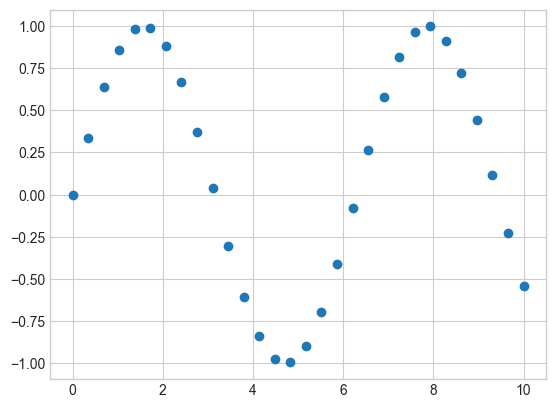

In [6]:
plt.scatter(x, y);


**La diferencia principal de ``plt.scatter`` con ``plt.plot`` es que se puede utilizar para crear gráficos de dispersión donde las propiedades de cada punto individual (tamaño, color de relleno, color de borde, etc.) pueden ser controladas individualmente o asignadas a datos.** De hecho, gracias a esto creamos los diagramas de burbujas donde el tamaño de los puntos depende de una tercera variable.

Veámoslo creando un gráfico de dispersión aleatorio con puntos de muchos colores y tamaños.
Para poder ver mejor los resultados superpuestos, también usaremos la palabra clave ``alpha`` para ajustar el nivel de transparencia:


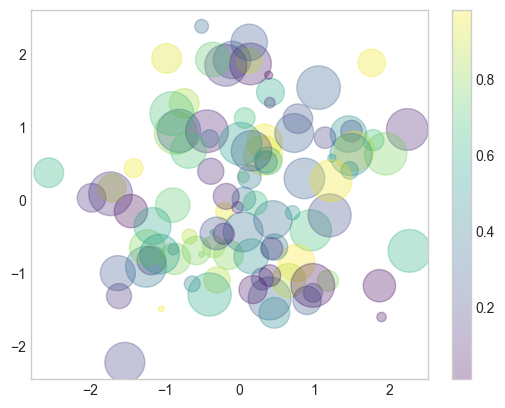

In [7]:
rng = np.random.RandomState(0)
plt.grid(False)
x = rng.randn(100) # edades
y = rng.randn(100) # alturas
colors = rng.rand(100) # país
sizes = 1000 * rng.rand(100) # número de personas

plt.scatter(x, y, c=colors, s=sizes, alpha=0.3,
            cmap='viridis');
plt.colorbar();

Fíjate en que el argumento de color se asigna automáticamente a una escala de colores (que mostramos con ``colorbar()``) y en que el tamaño se indica en puntos. Así, el color y el tamaño de los puntos sirven para transmitir información y visualizar datos multidimensionales.

Para verlo con un dataset real, usemos otro de los datasets "hello, world" junto con el del titanic: el dataset iris. En él tenemos tres especies de flores de la misma familia. Vamos a enfrentar la longitud del sépalo con la longitud del pétalo, pintar cada especie de un color y regular el tamaño de los puntos con la anchura del pétalo:

In [8]:
df_iris = pd.read_csv("../data/iris.csv")
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,iris_class
0,5.1,3.5,1.4,0.2,0.0,setosa
1,4.9,3.0,1.4,0.2,0.0,setosa
2,4.7,3.2,1.3,0.2,0.0,setosa
3,4.6,3.1,1.5,0.2,0.0,setosa
4,5.0,3.6,1.4,0.2,0.0,setosa


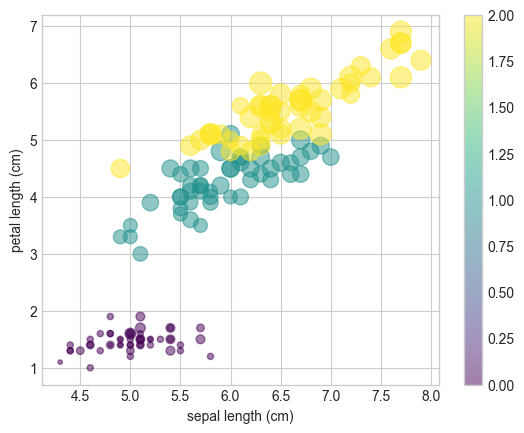

In [9]:
plt.scatter(df_iris["sepal length (cm)"], df_iris["petal length (cm)"], alpha=0.5,
            s=100*df_iris["petal width (cm)"], c=df_iris["target"], cmap='viridis')
plt.xlabel("sepal length (cm)")
plt.ylabel("petal length (cm)")
plt.colorbar();

Podemos ver que este gráfico de dispersión nos ha dado la capacidad de **explorar simultáneamente cuatro dimensiones diferentes de los datos:**
la ubicación (x, y) de cada punto corresponde a la longitud del sépalo y a la del pétalo, el tamaño del punto está relacionado con la anchura del pétalo, y el color está relacionado con la especie particular de flor.
Gráficos de dispersión multicolores y multifuncionales como este pueden ser útiles tanto para la exploración como para la presentación de datos.

### ``plot`` frente a ``scatter``: una nota sobre la eficiencia

Aparte de las distintas funcionalidades de ``plt.plot`` y ``plt.scatter``, **¿por qué elegir uno u otro?** Con pocos datos no importa demasiado, pero cuando el dataset supera unos pocos miles de puntos **``plt.plot`` puede ser notablemente más eficiente que ``plt.scatter``.
La razón es que ``plt.scatter`` puede dibujar cada punto con un tamaño y/o color distinto, así que tiene que construir cada punto por separado.**
En ``plt.plot``, en cambio, todos los puntos son copias unos de otros, de modo que su aspecto se calcula una sola vez para todo el conjunto.
Por eso, con datasets grandes es preferible ``plt.plot``.